## 1. Set up & File Paths

In [57]:
# Import required libraries and setting file paths.

from pathlib import Path
from collections import Counter
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    100
)

pd.set_option(
    "display.max_colwidth",
    100
)

sns.set_theme(
    style="whitegrid"
)

# Main dataset file
DATASET_DIR = Path(
    "/Users/purnaperamune/Documents/GitHub/"
    "P000464SE-Modern-Transformer-Models-for-"
    "Depression-Anxiety-Detection/dataset"
)

EXPLORATION_OUTPUT_DIR = (
    DATASET_DIR
    / "exploration_outputs"
)

EXPLORATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


FILE_PATHS = {
    "patients": (
        DATASET_DIR
        / "patients.csv"
    ),

    "admissions": (
        DATASET_DIR
        / "admissions.csv.gz"
    ),

    "diagnoses_icd": (
        DATASET_DIR
        / "diagnoses_icd.csv.gz"
    ),

    "d_icd_diagnoses": (
        DATASET_DIR
        / "d_icd_diagnoses.csv.gz"
    ),

    "discharge": (
        DATASET_DIR
        / "discharge.csv.gz"
    ),

    "discharge_detail": (
        DATASET_DIR
        / "discharge_detail.csv.gz"
    )
}


print(
    "Dataset directory:",
    DATASET_DIR
)

print(
    "Dataset directory exists:",
    DATASET_DIR.exists()
)

print(
    "Exploration output directory:",
    EXPLORATION_OUTPUT_DIR
)

Dataset directory: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset
Dataset directory exists: True
Exploration output directory: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/exploration_outputs


In [58]:
# Verify if all required files are present and exploring file sizes.

file_inventory_records = []

missing_files = []


for table_name, file_path in FILE_PATHS.items():

    file_exists = file_path.exists()

    if file_exists:

        file_size_mb = (
            file_path.stat().st_size
            / 1_000_000
        )

    else:

        file_size_mb = np.nan

        missing_files.append(
            str(file_path)
        )

    file_inventory_records.append(
        {
            "table": table_name,
            "filename": file_path.name,
            "exists": file_exists,
            "compressed_file_size_mb": file_size_mb
        }
    )


file_inventory = pd.DataFrame(
    file_inventory_records
)


display(
    file_inventory
)


if missing_files:

    raise FileNotFoundError(
        "The following files were not found:\n"
        + "\n".join(missing_files)
    )


print(
    "All expected files were found."
)

,table,filename,exists,compressed_file_size_mb
0,patients,patients.csv,True,12.051137
1,admissions,admissions.csv.gz,True,19.928140
2,diagnoses_icd,diagnoses_icd.csv.gz,True,33.564802
3,d_icd_diagnoses,d_icd_diagnoses.csv.gz,True,0.876360
4,discharge,discharge.csv.gz,True,1139.203149
5,discharge_detail,discharge_detail.csv.gz,True,0.789351


All expected files were found.


## 2. Overall Table Exploration

In [59]:
# Display first 5 records of all dataset files.

table_previews = {}


for table_name, file_path in FILE_PATHS.items():

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"TABLE: {table_name}"
    )

    print(
        f"FILE: {file_path.name}"
    )

    print(
        "=" * 80
    )


    if not file_path.exists():

        print(
            f"File not found: {file_path}"
        )

        continue


    try:

        # Read only the first five records.
        preview_dataframe = pd.read_csv(
            file_path,
            nrows=5,
            low_memory=False,
        )


        # Store the preview for later use.
        table_previews[
            table_name
        ] = preview_dataframe


        print(
            "Number of displayed records:",
            len(
                preview_dataframe
            )
        )

        print(
            "Number of columns:",
            len(
                preview_dataframe.columns
            )
        )

        print(
            "Columns:"
        )

        print(
            preview_dataframe.columns.tolist()
        )


        display(
            preview_dataframe
        )


    except Exception as error:

        print(
            f"Unable to read {table_name}:"
        )

        print(
            error
        )


print(
    "\nFinished displaying the first five "
    "records from all available tables."
)


TABLE: patients
FILE: patients.csv
Number of displayed records: 5
Number of columns: 6
Columns:
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']


,subject_id,gender,anchor_age,anchor_year,anchor_year_group,dod
0,10000032,F,52,2180,2014 - 2016,2180-09-09
1,10000048,F,23,2126,2008 - 2010,NaN
2,10000058,F,33,2168,2020 - 2022,NaN
3,10000068,F,19,2160,2008 - 2010,NaN
4,10000084,M,72,2160,2017 - 2019,2161-02-13



TABLE: admissions
FILE: admissions.csv.gz
Number of displayed records: 5
Number of columns: 16
Columns:
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']


,subject_id,hadm_id,admittime,dischtime,deathtime,admission_type,admit_provider_id,admission_location,discharge_location,insurance,language,marital_status,race,edregtime,edouttime,hospital_expire_flag
0,10000032,22595853,2180-05-06 22:23:00,2180-05-07 17:15:00,NaN,URGENT,P49AFC,TRANSFER FROM HOSPITAL,HOME,Medicaid,English,WIDOWED,WHITE,2180-05-06 19:17:00,2180-05-06 23:30:00,0
1,10000032,22841357,2180-06-26 18:27:00,2180-06-27 18:49:00,NaN,EW EMER.,P784FA,EMERGENCY ROOM,HOME,Medicaid,English,WIDOWED,WHITE,2180-06-26 15:54:00,2180-06-26 21:31:00,0
2,10000032,25742920,2180-08-05 23:44:00,2180-08-07 17:50:00,NaN,EW EMER.,P19UTS,EMERGENCY ROOM,HOSPICE,Medicaid,English,WIDOWED,WHITE,2180-08-05 20:58:00,2180-08-06 01:44:00,0
3,10000032,29079034,2180-07-23 12:35:00,2180-07-25 17:55:00,NaN,EW EMER.,P06OTX,EMERGENCY ROOM,HOME,Medicaid,English,WIDOWED,WHITE,2180-07-23 05:54:00,2180-07-23 14:00:00,0
4,10000068,25022803,2160-03-03 23:16:00,2160-03-04 06:26:00,NaN,EU OBSERVATION,P39NWO,EMERGENCY ROOM,NaN,NaN,English,SINGLE,WHITE,2160-03-03 21:55:00,2160-03-04 06:26:00,0



TABLE: diagnoses_icd
FILE: diagnoses_icd.csv.gz
Number of displayed records: 5
Number of columns: 5
Columns:
['subject_id', 'hadm_id', 'seq_num', 'icd_code', 'icd_version']


...


TABLE: discharge
FILE: discharge.csv.gz
Number of displayed records: 5
Number of columns: 8
Columns:
['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime', 'text']


,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime,text
0,10000032-DS-21,10000032,22595853,DS,21,2180-05-07 00:00:00,2180-05-09 15:26:00,\nName: ___ Unit No: ___\n \nAdmission Date: ___ Discharge...
1,10000032-DS-22,10000032,22841357,DS,22,2180-06-27 00:00:00,2180-07-01 10:15:00,\nName: ___ Unit No: ___\n \nAdmission Date: ___ Discharge...
2,10000032-DS-23,10000032,29079034,DS,23,2180-07-25 00:00:00,2180-07-25 21:42:00,\nName: ___ Unit No: ___\n \nAdmission Date: ___ Discharge...
3,10000032-DS-24,10000032,25742920,DS,24,2180-08-07 00:00:00,2180-08-10 05:43:00,\nName: ___ Unit No: ___\n \nAdmission Date: ___ Discharge...
4,10000084-DS-17,10000084,23052089,DS,17,2160-11-25 00:00:00,2160-11-25 15:09:00,\nName: ___ Unit No: ___\n \nAdmission Date: ___ Discharge ...



TABLE: discharge_detail
FILE: discharge_detail.csv.gz
Number of displayed records: 5
Number of columns: 5
Columns:
['note_id', 'subject_id', 'field_name', 'field_value', 'field_ordinal']


,note_id,subject_id,field_name,field_value,field_ordinal
0,10000032-DS-21,10000032,author,___,1
1,10000032-DS-22,10000032,author,___,1
2,10000032-DS-23,10000032,author,___,1
3,10000032-DS-24,10000032,author,___,1
4,10000084-DS-17,10000084,author,___,1



Finished displaying the first five records from all available tables.


In [60]:
# Explore table schemas.

schema_records = []


for table_name, file_path in FILE_PATHS.items():

    sample = pd.read_csv(
        file_path,
        nrows=5
    )

    print(
        f"\n{'=' * 70}"
    )

    print(
        table_name.upper()
    )

    print(
        f"{'=' * 70}"
    )

    print(
        "Columns:"
    )

    print(
        sample.columns.tolist()
    )

    print(
        "\nInferred data types:"
    )

    print(
        sample.dtypes
    )

    for column_name in sample.columns:

        schema_records.append(
            {
                "table": table_name,
                "column": column_name,
                "sample_inferred_dtype": str(
                    sample[column_name].dtype
                )
            }
        )


schema_summary = pd.DataFrame(
    schema_records
)


display(
    schema_summary
)


PATIENTS
Columns:
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']

Inferred data types:
subject_id           int64
gender                 str
anchor_age           int64
anchor_year          int64
anchor_year_group      str
dod                    str
dtype: object

ADMISSIONS
Columns:
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']

Inferred data types:
subject_id                int64
hadm_id                   int64
admittime                   str
dischtime                   str
deathtime               float64
admission_type              str
admit_provider_id           str
admission_location          str
discharge_location          str
insurance                   str
language                    str
marital_status              str
race                     

,table,column,sample_inferred_dtype
0,patients,subject_id,int64
1,patients,gender,str
2,patients,anchor_age,int64
3,patients,anchor_year,int64
4,patients,anchor_year_group,str
5,patients,dod,str
6,admissions,subject_id,int64
7,admissions,hadm_id,int64
8,admissions,admittime,str
9,admissions,dischtime,str


## 3. Patients Table Exploration

In [61]:
# Explore Patients table - patients.csv

patients = pd.read_csv(
    FILE_PATHS["patients"]
)


patient_row_count = len(
    patients
)

patient_unique_subject_count = (
    patients["subject_id"]
    .nunique(
        dropna=True
    )
)

patient_missing_subject_count = (
    patients["subject_id"]
    .isna()
    .sum()
)

patient_duplicate_subject_count = (
    patients["subject_id"]
    .duplicated()
    .sum()
)


print(
    "Patients table shape:",
    patients.shape
)

print(
    "Unique patients:",
    patient_unique_subject_count
)

print(
    "Missing subject IDs:",
    patient_missing_subject_count
)

print(
    "Duplicate subject IDs:",
    patient_duplicate_subject_count
)


patients_missing_summary = pd.DataFrame(
    {
        "missing_count": (
            patients
            .isna()
            .sum()
        ),

        "missing_percentage": (
            patients
            .isna()
            .mean()
            .mul(100)
            .round(2)
        )
    }
).sort_values(
    by="missing_percentage",
    ascending=False
)


display(
    patients_missing_summary
)


patient_subject_ids = set(
    patients["subject_id"]
    .dropna()
    .astype("int64")
)

Patients table shape: (364627, 6)
Unique patients: 364627
Missing subject IDs: 0
Duplicate subject IDs: 0


,missing_count,missing_percentage
dod,326326,89.5
subject_id,0,0.0
gender,0,0.0
anchor_age,0,0.0
anchor_year,0,0.0
anchor_year_group,0,0.0


Gender distribution:


,gender,patient_count,percentage
0,F,191984,52.65
1,M,172643,47.35


Anchor-age summary:


count    364627.000000
mean         48.875097
std          20.943316
min          18.000000
25%          29.000000
50%          48.000000
75%          65.000000
max          91.000000
Name: anchor_age, dtype: float64

Missing anchor ages: 0
Invalid anchor ages: 0
Patients with anchor age at least 65: 95715

Anchor-year groups:


,anchor_year_group,patient_count
0,2008 - 2010,101607
1,2011 - 2013,76266
2,2014 - 2016,71640
3,2017 - 2019,65941
4,2020 - 2022,49173


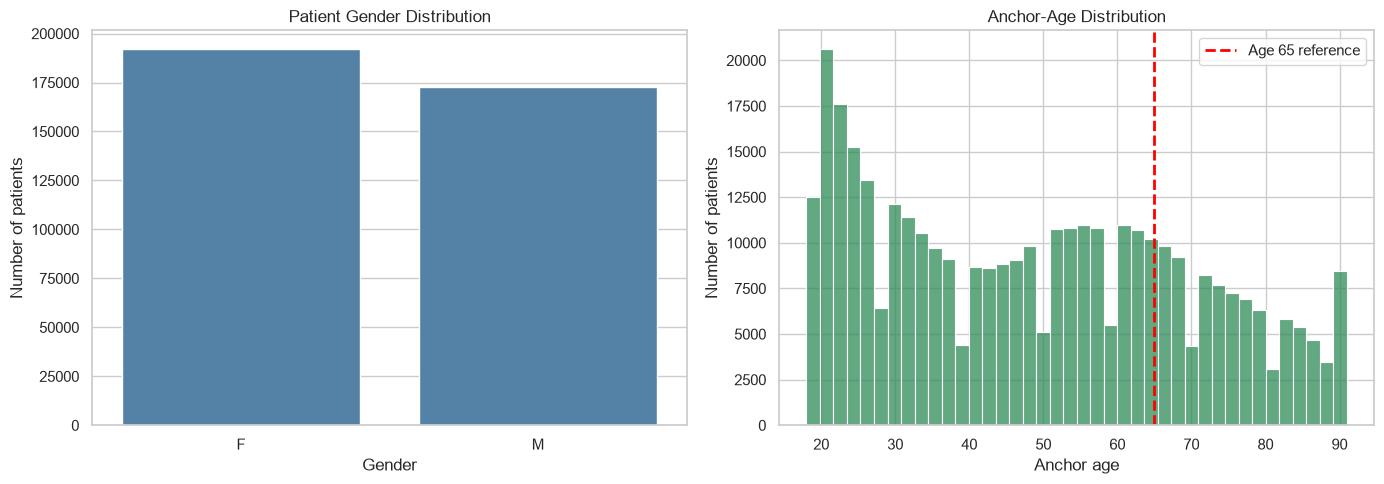

In [62]:
# Explore Patients demographics & anchor age

gender_summary = (
    patients["gender"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("gender")
    .reset_index(name="patient_count")
)


gender_summary[
    "percentage"
] = (
    gender_summary["patient_count"]
    .div(len(patients))
    .mul(100)
    .round(2)
)


print(
    "Gender distribution:"
)

display(
    gender_summary
)


print(
    "Anchor-age summary:"
)

display(
    patients["anchor_age"]
    .describe()
)


invalid_anchor_ages = (
    patients[
        patients["anchor_age"]
        .notna()
        &
        (
            (
                patients["anchor_age"]
                < 0
            )
            |
            (
                patients["anchor_age"]
                > 91
            )
        )
    ]
)


print(
    "Missing anchor ages:",
    patients["anchor_age"]
    .isna()
    .sum()
)

print(
    "Invalid anchor ages:",
    len(invalid_anchor_ages)
)

print(
    "Patients with anchor age at least 65:",
    (
        patients["anchor_age"]
        >= 65
    )
    .sum()
)


anchor_year_group_summary = (
    patients["anchor_year_group"]
    .fillna("Missing")
    .value_counts()
    .sort_index()
    .rename_axis("anchor_year_group")
    .reset_index(name="patient_count")
)


print(
    "\nAnchor-year groups:"
)

display(
    anchor_year_group_summary
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


sns.barplot(
    data=gender_summary,
    x="gender",
    y="patient_count",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title(
    "Patient Gender Distribution"
)

axes[0].set_xlabel(
    "Gender"
)

axes[0].set_ylabel(
    "Number of patients"
)


sns.histplot(
    data=patients,
    x="anchor_age",
    bins=40,
    color="seagreen",
    edgecolor="white",
    ax=axes[1]
)

axes[1].axvline(
    x=65,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Age 65 reference"
)

axes[1].set_title(
    "Anchor-Age Distribution"
)

axes[1].set_xlabel(
    "Anchor age"
)

axes[1].set_ylabel(
    "Number of patients"
)

axes[1].legend()


plt.tight_layout()

plt.show()

## 4. Admissions Table Exploration

In [63]:
# Explore Admission table - admissions.csv.gz

admissions = pd.read_csv(
    FILE_PATHS["admissions"]
)


date_columns = [
    "admittime",
    "dischtime",
    "deathtime",
    "edregtime",
    "edouttime"
]


for column_name in date_columns:

    if column_name in admissions.columns:

        admissions[column_name] = pd.to_datetime(
            admissions[column_name],
            errors="coerce"
        )


admission_row_count = len(
    admissions
)

admission_unique_hadm_count = (
    admissions["hadm_id"]
    .nunique(
        dropna=True
    )
)

admission_unique_subject_count = (
    admissions["subject_id"]
    .nunique(
        dropna=True
    )
)

admission_missing_hadm_count = (
    admissions["hadm_id"]
    .isna()
    .sum()
)

admission_duplicate_hadm_count = (
    admissions["hadm_id"]
    .duplicated()
    .sum()
)


print(
    "Admissions table shape:",
    admissions.shape
)

print(
    "Unique admissions:",
    admission_unique_hadm_count
)

print(
    "Unique patients with admissions:",
    admission_unique_subject_count
)

print(
    "Missing admission IDs:",
    admission_missing_hadm_count
)

print(
    "Duplicate admission IDs:",
    admission_duplicate_hadm_count
)


admissions_missing_summary = pd.DataFrame(
    {
        "missing_count": (
            admissions
            .isna()
            .sum()
        ),

        "missing_percentage": (
            admissions
            .isna()
            .mean()
            .mul(100)
            .round(2)
        )
    }
).sort_values(
    by="missing_percentage",
    ascending=False
)


display(
    admissions_missing_summary
)


admission_subject_ids = set(
    admissions["subject_id"]
    .dropna()
    .astype("int64")
)

admission_hadm_ids = set(
    admissions["hadm_id"]
    .dropna()
    .astype("int64")
)


admission_subjects_missing_from_patients = (
    admission_subject_ids
    - patient_subject_ids
)


print(
    "Admission patients missing from patients table:",
    len(admission_subjects_missing_from_patients)
)

Admissions table shape: (546028, 16)
Unique admissions: 546028
Unique patients with admissions: 223452
Missing admission IDs: 0
Duplicate admission IDs: 0


,missing_count,missing_percentage
deathtime,534238,97.84
edregtime,166788,30.55
edouttime,166788,30.55
discharge_location,149818,27.44
marital_status,13619,2.49
insurance,9355,1.71
language,775,0.14
subject_id,0,0.00
hadm_id,0,0.00
admittime,0,0.00


Admission patients missing from patients table: 0


In [64]:
# Explore admissions and length of stay

admissions_per_patient = (
    admissions
    .groupby("subject_id")
    .size()
)


print(
    "Admissions per patient:"
)

display(
    admissions_per_patient.describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


if (
    "admittime" in admissions.columns
    and "dischtime" in admissions.columns
):

    admissions[
        "length_of_stay_days"
    ] = (
        admissions["dischtime"]
        - admissions["admittime"]
    ).dt.total_seconds() / 86_400

    print(
        "Hospital length-of-stay summary:"
    )

    display(
        admissions[
            "length_of_stay_days"
        ]
        .describe(
            percentiles=[
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )

    negative_length_of_stay_count = (
        admissions[
            "length_of_stay_days"
        ]
        .lt(0)
        .sum()
    )

    print(
        "Negative length-of-stay records:",
        negative_length_of_stay_count
    )


categorical_admission_columns = [
    "admission_type",
    "race",
    "marital_status"
]


for column_name in categorical_admission_columns:

    if column_name in admissions.columns:

        summary = (
            admissions[column_name]
            .fillna("Missing")
            .value_counts()
            .rename_axis(column_name)
            .reset_index(name="admission_count")
        )

        summary[
            "percentage"
        ] = (
            summary["admission_count"]
            .div(len(admissions))
            .mul(100)
            .round(2)
        )

        print(
            f"\n{column_name.upper()} DISTRIBUTION"
        )

        display(
            summary.head(20)
        )

Admissions per patient:


count    223452.000000
mean          2.443603
std           3.574410
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
90%           5.000000
95%           7.000000
99%          16.000000
max         238.000000
dtype: float64

Hospital length-of-stay summary:


count    546028.000000
mean          4.761742
std           7.207125
min          -0.945139
25%           1.128472
50%           2.818056
75%           5.621528
90%          10.138194
95%          15.423576
99%          33.920028
max         515.562500
Name: length_of_stay_days, dtype: float64

Negative length-of-stay records: 175

ADMISSION_TYPE DISTRIBUTION


,admission_type,admission_count,percentage
0,EW EMER.,177459,32.50
1,EU OBSERVATION,119456,21.88
2,OBSERVATION ADMIT,84437,15.46
3,URGENT,54929,10.06
4,SURGICAL SAME DAY ADMISSION,42898,7.86
5,DIRECT OBSERVATION,24551,4.50
6,DIRECT EMER.,21973,4.02
7,ELECTIVE,13130,2.40
8,AMBULATORY OBSERVATION,7195,1.32



RACE DISTRIBUTION


,race,admission_count,percentage
0,WHITE,336538,61.63
1,BLACK/AFRICAN AMERICAN,75482,13.82
2,OTHER,19788,3.62
3,WHITE - OTHER EUROPEAN,13972,2.56
4,UNKNOWN,13870,2.54
5,HISPANIC/LATINO - PUERTO RICAN,10903,2.00
6,HISPANIC OR LATINO,8287,1.52
7,ASIAN,7809,1.43
8,ASIAN - CHINESE,7644,1.40
9,WHITE - RUSSIAN,6597,1.21



MARITAL_STATUS DISTRIBUTION


,marital_status,admission_count,percentage
0,MARRIED,229134,41.96
1,SINGLE,206232,37.77
2,WIDOWED,56687,10.38
3,DIVORCED,40356,7.39
4,Missing,13619,2.49


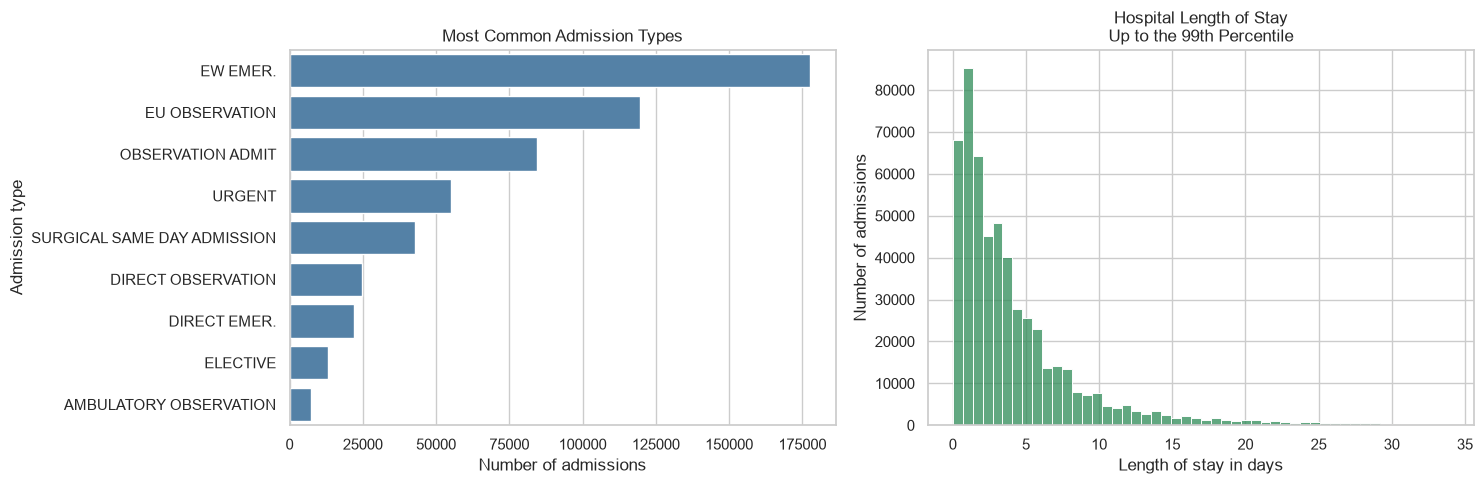

In [65]:
# Plot key admission characteristics and features.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


if "admission_type" in admissions.columns:

    admission_type_plot = (
        admissions["admission_type"]
        .fillna("Missing")
        .value_counts()
        .head(10)
        .rename_axis("admission_type")
        .reset_index(name="admission_count")
    )

    sns.barplot(
        data=admission_type_plot,
        x="admission_count",
        y="admission_type",
        color="steelblue",
        ax=axes[0]
    )

    axes[0].set_title(
        "Most Common Admission Types"
    )

    axes[0].set_xlabel(
        "Number of admissions"
    )

    axes[0].set_ylabel(
        "Admission type"
    )

else:

    axes[0].set_visible(
        False
    )


if "length_of_stay_days" in admissions.columns:

    valid_lengths = (
        admissions.loc[
            admissions["length_of_stay_days"]
            .ge(0),
            "length_of_stay_days"
        ]
        .dropna()
    )

    if not valid_lengths.empty:

        length_limit_99 = (
            valid_lengths
            .quantile(0.99)
        )

        sns.histplot(
            valid_lengths[
                valid_lengths
                <= length_limit_99
            ],
            bins=50,
            color="seagreen",
            ax=axes[1]
        )

        axes[1].set_title(
            "Hospital Length of Stay\n"
            "Up to the 99th Percentile"
        )

        axes[1].set_xlabel(
            "Length of stay in days"
        )

        axes[1].set_ylabel(
            "Number of admissions"
        )

else:

    axes[1].set_visible(
        False
    )


plt.tight_layout()

plt.show()

In [66]:
del admissions

gc.collect()

print(
    "Admissions dataframe removed from memory."
)

Admissions dataframe removed from memory.


## 5. ICD Diagnosis Table Exploration

In [67]:
# Explore ICD diagnose table - diagnoses_icd.csv.gz

diagnoses = pd.read_csv(
    FILE_PATHS["diagnoses_icd"],
    usecols=[
        "subject_id",
        "hadm_id",
        "seq_num",
        "icd_code",
        "icd_version"
    ],
    dtype={
        "subject_id": "Int64",
        "hadm_id": "Int64",
        "seq_num": "Int64",
        "icd_code": "string",
        "icd_version": "Int64"
    }
)


diagnosis_row_count = len(
    diagnoses
)

diagnosis_unique_subject_count = (
    diagnoses["subject_id"]
    .nunique(
        dropna=True
    )
)

diagnosis_unique_hadm_count = (
    diagnoses["hadm_id"]
    .nunique(
        dropna=True
    )
)

duplicate_diagnosis_row_count = (
    diagnoses
    .duplicated()
    .sum()
)


print(
    "Diagnoses table shape:",
    diagnoses.shape
)

print(
    "Unique diagnosis patients:",
    diagnosis_unique_subject_count
)

print(
    "Unique diagnosed admissions:",
    diagnosis_unique_hadm_count
)

print(
    "Exact duplicate diagnosis rows:",
    duplicate_diagnosis_row_count
)


diagnoses_missing_summary = pd.DataFrame(
    {
        "missing_count": (
            diagnoses
            .isna()
            .sum()
        ),

        "missing_percentage": (
            diagnoses
            .isna()
            .mean()
            .mul(100)
            .round(2)
        )
    }
).sort_values(
    by="missing_percentage",
    ascending=False
)


display(
    diagnoses_missing_summary
)


print(
    "ICD version distribution:"
)

display(
    diagnoses[
        "icd_version"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
)


diagnoses_per_admission = (
    diagnoses
    .groupby("hadm_id")
    .size()
)


print(
    "Diagnosis records per admission:"
)

display(
    diagnoses_per_admission.describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


diagnosis_subject_ids = set(
    diagnoses["subject_id"]
    .dropna()
    .astype("int64")
)

diagnosis_hadm_ids = set(
    diagnoses["hadm_id"]
    .dropna()
    .astype("int64")
)

Diagnoses table shape: (6364488, 5)
Unique diagnosis patients: 223291
Unique diagnosed admissions: 545497
Exact duplicate diagnosis rows: 0


,missing_count,missing_percentage
subject_id,0,0.0
hadm_id,0,0.0
seq_num,0,0.0
icd_code,0,0.0
icd_version,0,0.0


ICD version distribution:


icd_version
9     2908741
10    3455747
Name: count, dtype: Int64

Diagnosis records per admission:


count    545497.000000
mean         11.667320
std           7.625992
min           1.000000
25%           6.000000
50%          10.000000
75%          16.000000
90%          22.000000
95%          27.000000
99%          36.000000
max          57.000000
dtype: float64

In [68]:
# Diagnose sequence numbers.

print(
    "Diagnosis sequence-number summary:"
)

display(
    diagnoses[
        "seq_num"
    ]
    .describe()
)


primary_diagnosis_count = (
    diagnoses[
        "seq_num"
    ]
    .eq(1)
    .sum()
)


print(
    "Rows with seq_num equal to 1:",
    primary_diagnosis_count
)

print(
    "Percentage of rows with seq_num equal to 1:",
    round(
        (
            primary_diagnosis_count
            / len(diagnoses)
        )
        * 100,
        2
    )
)


diagnosed_admissions_missing_from_admissions = (
    diagnosis_hadm_ids
    - admission_hadm_ids
)


admissions_without_diagnosis_records = (
    admission_hadm_ids
    - diagnosis_hadm_ids
)


print(
    "Diagnosed admission IDs missing from admissions table:",
    len(
        diagnosed_admissions_missing_from_admissions
    )
)

print(
    "Admission IDs without diagnosis records:",
    len(
        admissions_without_diagnosis_records
    )
)

Diagnosis sequence-number summary:


count    6364488.0
mean      8.825529
std       6.858762
min            1.0
25%            4.0
50%            7.0
75%           12.0
max           39.0
Name: seq_num, dtype: Float64

Rows with seq_num equal to 1: 545507
Percentage of rows with seq_num equal to 1: 8.57
Diagnosed admission IDs missing from admissions table: 0
Admission IDs without diagnosis records: 531


In [69]:
# Explore ICD dictionary table - d_icd_diagnoses.csv.gz

diagnosis_dictionary = pd.read_csv(
    FILE_PATHS["d_icd_diagnoses"],
    dtype={
        "icd_code": "string",
        "icd_version": "Int64",
        "long_title": "string"
    }
)


diagnosis_dictionary_row_count = len(
    diagnosis_dictionary
)


diagnoses[
    "icd_code_clean"
] = (
    diagnoses["icd_code"]
    .astype("string")
    .str
    .upper()
    .str
    .replace(
        ".",
        "",
        regex=False
    )
    .str
    .strip()
)


diagnosis_dictionary[
    "icd_code_clean"
] = (
    diagnosis_dictionary["icd_code"]
    .astype("string")
    .str
    .upper()
    .str
    .replace(
        ".",
        "",
        regex=False
    )
    .str
    .strip()
)


dictionary_duplicate_key_count = (
    diagnosis_dictionary
    .duplicated(
        subset=[
            "icd_code_clean",
            "icd_version"
        ]
    )
    .sum()
)


print(
    "Diagnosis dictionary shape:",
    diagnosis_dictionary.shape
)

print(
    "Duplicate code/version keys:",
    dictionary_duplicate_key_count
)

print(
    "Missing long titles:",
    diagnosis_dictionary[
        "long_title"
    ]
    .isna()
    .sum()
)


diagnosis_code_counts = (
    diagnoses
    .dropna(
        subset=[
            "icd_code_clean",
            "icd_version"
        ]
    )
    .groupby(
        [
            "icd_code_clean",
            "icd_version"
        ],
        as_index=False
    )
    .size()
    .rename(
        columns={
            "size": "diagnosis_row_count"
        }
    )
)


dictionary_lookup = (
    diagnosis_dictionary[
        [
            "icd_code_clean",
            "icd_version",
            "long_title"
        ]
    ]
    .drop_duplicates(
        subset=[
            "icd_code_clean",
            "icd_version"
        ]
    )
)


diagnosis_code_match = (
    diagnosis_code_counts
    .merge(
        dictionary_lookup,
        on=[
            "icd_code_clean",
            "icd_version"
        ],
        how="left",
        validate="many_to_one"
    )
)


matched_unique_codes = (
    diagnosis_code_match[
        "long_title"
    ]
    .notna()
    .sum()
)


total_unique_codes = len(
    diagnosis_code_match
)


matched_diagnosis_rows = (
    diagnosis_code_match.loc[
        diagnosis_code_match[
            "long_title"
        ]
        .notna(),
        "diagnosis_row_count"
    ]
    .sum()
)


total_diagnosis_rows_with_codes = (
    diagnosis_code_match[
        "diagnosis_row_count"
    ]
    .sum()
)


print(
    "Unique code/version combinations:",
    total_unique_codes
)

print(
    "Matched unique code/version combinations:",
    matched_unique_codes
)

print(
    "Unique-code match percentage:",
    round(
        (
            matched_unique_codes
            / total_unique_codes
        )
        * 100,
        2
    )
)

print(
    "Diagnosis-row match percentage:",
    round(
        (
            matched_diagnosis_rows
            / total_diagnosis_rows_with_codes
        )
        * 100,
        2
    )
)


most_common_diagnoses = (
    diagnosis_code_match
    .sort_values(
        by="diagnosis_row_count",
        ascending=False
    )
    .head(20)
)


display(
    most_common_diagnoses
)

Diagnosis dictionary shape: (112107, 4)
Duplicate code/version keys: 0
Missing long titles: 0
Unique code/version combinations: 28583
Matched unique code/version combinations: 28583
Unique-code match percentage: 100.0
Diagnosis-row match percentage: 100.0


,icd_code_clean,icd_version,diagnosis_row_count,long_title
2801,4019,9,102368,Unspecified essential hypertension
10049,E785,10,84570,"Hyperlipidemia, unspecified"
12953,I10,10,83775,Essential (primary) hypertension
1342,2724,9,67293,Other and unspecified hyperlipidemia
28363,Z87891,10,62806,Personal history of nicotine dependence
14396,K219,10,56157,Gastro-esophageal reflux disease without esophagitis
3552,53081,9,48628,Esophageal reflux
1197,25000,9,43077,"Diabetes mellitus without mention of complication, type II or unspecified type, not stated as un..."
11150,F329,10,41876,"Major depressive disorder, single episode, unspecified"
13001,I2510,10,41550,Atherosclerotic heart disease of native coronary artery without angina pectoris


In [70]:
del diagnoses
del diagnosis_dictionary
del diagnosis_code_counts
del dictionary_lookup

gc.collect()

print(
    "Large diagnosis dataframes removed from memory."
)

Large diagnosis dataframes removed from memory.


## 6. Discharge Summary Table Exploration

In [71]:
# Explore Discharge summary table - discharge.csv.gz

discharge_header = pd.read_csv(
    FILE_PATHS["discharge"],
    nrows=0
)


available_discharge_columns = (
    discharge_header
    .columns
    .tolist()
)


required_discharge_columns = [
    "note_id",
    "subject_id",
    "hadm_id",
    "text"
]


missing_discharge_columns = [
    column_name
    for column_name in required_discharge_columns
    if column_name
    not in available_discharge_columns
]


print(
    "Available discharge columns:"
)

print(
    available_discharge_columns
)


if missing_discharge_columns:

    raise ValueError(
        "The following required discharge columns are missing: "
        + ", ".join(
            missing_discharge_columns
        )
    )


print(
    "All required discharge columns are available."
)

Available discharge columns:
['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime', 'text']
All required discharge columns are available.


In [72]:
# Explore discharge metadata.

discharge_sample = pd.read_csv(
    FILE_PATHS["discharge"],
    nrows=10
)


safe_discharge_columns = [
    column_name
    for column_name in discharge_sample.columns
    if column_name != "text"
]


print(
    "Discharge sample shape:",
    discharge_sample.shape
)

print(
    "Displayed columns:",
    safe_discharge_columns
)


display(
    discharge_sample[
        safe_discharge_columns
    ]
)


if "text" in discharge_sample.columns:

    discharge_sample[
        "sample_character_count"
    ] = (
        discharge_sample["text"]
        .fillna("")
        .astype(str)
        .str
        .len()
    )

    discharge_sample[
        "sample_word_count"
    ] = (
        discharge_sample["text"]
        .fillna("")
        .astype(str)
        .str
        .count(r"\S+")
    )

    length_columns = [
        column_name
        for column_name in [
            "note_id",
            "subject_id",
            "hadm_id",
            "sample_character_count",
            "sample_word_count"
        ]
        if column_name in discharge_sample.columns
    ]

    display(
        discharge_sample[
            length_columns
        ]
    )


del discharge_sample

gc.collect()

Discharge sample shape: (10, 8)
Displayed columns: ['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime']


,note_id,subject_id,hadm_id,note_type,note_seq,charttime,storetime
0,10000032-DS-21,10000032,22595853,DS,21,2180-05-07 00:00:00,2180-05-09 15:26:00
1,10000032-DS-22,10000032,22841357,DS,22,2180-06-27 00:00:00,2180-07-01 10:15:00
2,10000032-DS-23,10000032,29079034,DS,23,2180-07-25 00:00:00,2180-07-25 21:42:00
3,10000032-DS-24,10000032,25742920,DS,24,2180-08-07 00:00:00,2180-08-10 05:43:00
4,10000084-DS-17,10000084,23052089,DS,17,2160-11-25 00:00:00,2160-11-25 15:09:00
5,10000117-DS-21,10000117,22927623,DS,21,2181-11-15 00:00:00,2181-11-15 15:04:00
6,10000117-DS-22,10000117,27988844,DS,22,2183-09-21 00:00:00,2183-09-29 16:23:00
7,10000248-DS-10,10000248,20600184,DS,10,2192-11-30 00:00:00,2192-11-30 19:49:00
8,10000560-DS-15,10000560,28979390,DS,15,2189-10-17 00:00:00,2189-10-17 13:47:00
9,10000764-DS-11,10000764,27897940,DS,11,2132-10-19 00:00:00,2132-10-19 18:50:00


,note_id,subject_id,hadm_id,sample_character_count,sample_word_count
0,10000032-DS-21,10000032,22595853,7530,1204
1,10000032-DS-22,10000032,22841357,10922,1696
2,10000032-DS-23,10000032,29079034,10608,1633
3,10000032-DS-24,10000032,25742920,10348,1573
4,10000084-DS-17,10000084,23052089,9293,1396
5,10000117-DS-21,10000117,22927623,4637,675
6,10000117-DS-22,10000117,27988844,6288,973
7,10000248-DS-10,10000248,20600184,8031,1183
8,10000560-DS-15,10000560,28979390,3525,514
9,10000764-DS-11,10000764,27897940,9949,1462


4

In [73]:
# Explore discharge file in chunks

CHUNK_SIZE = 5_000


discharge_row_count = 0

discharge_missing_note_id_count = 0
discharge_missing_subject_id_count = 0
discharge_missing_hadm_id_count = 0
discharge_missing_text_count = 0
discharge_empty_text_count = 0

discharge_nonmissing_note_id_count = 0
discharge_usable_text_count = 0

discharge_note_ids = set()
discharge_subject_ids = set()
discharge_hadm_ids = set()
discharge_text_hashes = set()

note_counts_by_admission = Counter()

discharge_character_counts = []
discharge_word_counts = []


start_time = time.time()


chunk_reader = pd.read_csv(
    FILE_PATHS["discharge"],
    usecols=[
        "note_id",
        "subject_id",
        "hadm_id",
        "text"
    ],
    dtype={
        "note_id": "string",
        "subject_id": "Int64",
        "hadm_id": "Int64",
        "text": "string"
    },
    chunksize=CHUNK_SIZE
)


for chunk_number, chunk in enumerate(
    chunk_reader,
    start=1
):

    discharge_row_count += len(
        chunk
    )

    discharge_missing_note_id_count += (
        chunk["note_id"]
        .isna()
        .sum()
    )

    discharge_missing_subject_id_count += (
        chunk["subject_id"]
        .isna()
        .sum()
    )

    discharge_missing_hadm_id_count += (
        chunk["hadm_id"]
        .isna()
        .sum()
    )

    discharge_missing_text_count += (
        chunk["text"]
        .isna()
        .sum()
    )


    valid_note_ids = (
        chunk["note_id"]
        .dropna()
        .astype(str)
    )

    discharge_nonmissing_note_id_count += len(
        valid_note_ids
    )

    discharge_note_ids.update(
        valid_note_ids.tolist()
    )


    valid_subject_ids = (
        chunk["subject_id"]
        .dropna()
        .astype("int64")
    )

    discharge_subject_ids.update(
        valid_subject_ids.tolist()
    )


    valid_hadm_ids = (
        chunk["hadm_id"]
        .dropna()
        .astype("int64")
    )

    discharge_hadm_ids.update(
        valid_hadm_ids.tolist()
    )


    admission_note_counts_chunk = (
        valid_hadm_ids
        .value_counts()
        .to_dict()
    )

    note_counts_by_admission.update(
        admission_note_counts_chunk
    )


    text_values = (
        chunk["text"]
        .fillna("")
        .astype("string")
    )

    stripped_text = (
        text_values
        .str
        .strip()
    )

    usable_text_mask = (
        stripped_text
        .str
        .len()
        .gt(0)
    )

    missing_or_empty_mask = (
        ~usable_text_mask
    )

    discharge_empty_text_count += (
        missing_or_empty_mask.sum()
        - chunk["text"].isna().sum()
    )

    usable_text = (
        stripped_text[
            usable_text_mask
        ]
    )

    discharge_usable_text_count += len(
        usable_text
    )


    character_counts_chunk = (
        usable_text
        .str
        .len()
        .astype("int64")
    )

    word_counts_chunk = (
        usable_text
        .str
        .count(r"\S+")
        .astype("int64")
    )

    discharge_character_counts.extend(
        character_counts_chunk.tolist()
    )

    discharge_word_counts.extend(
        word_counts_chunk.tolist()
    )


    text_hashes_chunk = (
        pd.util
        .hash_pandas_object(
            usable_text,
            index=False
        )
        .astype("uint64")
    )

    discharge_text_hashes.update(
        text_hashes_chunk.tolist()
    )


    if chunk_number % 20 == 0:

        print(
            f"Processed {discharge_row_count:,} "
            f"discharge-summary rows"
        )


elapsed_minutes = (
    time.time()
    - start_time
) / 60


print(
    "\nDischarge exploration completed."
)

print(
    f"Elapsed time: {elapsed_minutes:.2f} minutes"
)

Processed 100,000 discharge-summary rows
Processed 200,000 discharge-summary rows
Processed 300,000 discharge-summary rows

Discharge exploration completed.
Elapsed time: 1.11 minutes


In [74]:
# Summary of discharge notes

duplicate_note_id_count = (
    discharge_nonmissing_note_id_count
    - len(discharge_note_ids)
)

potential_duplicate_text_count = (
    discharge_usable_text_count
    - len(discharge_text_hashes)
)


discharge_quality_summary = pd.DataFrame(
    {
        "measure": [
            "Total discharge rows",
            "Unique note IDs",
            "Missing note IDs",
            "Duplicate note IDs",
            "Unique patients",
            "Unique admission IDs",
            "Missing patient IDs",
            "Missing admission IDs",
            "Missing text values",
            "Empty text values",
            "Usable text values",
            "Potential exact duplicate texts"
        ],

        "value": [
            discharge_row_count,
            len(discharge_note_ids),
            discharge_missing_note_id_count,
            duplicate_note_id_count,
            len(discharge_subject_ids),
            len(discharge_hadm_ids),
            discharge_missing_subject_id_count,
            discharge_missing_hadm_id_count,
            discharge_missing_text_count,
            discharge_empty_text_count,
            discharge_usable_text_count,
            potential_duplicate_text_count
        ]
    }
)


display(
    discharge_quality_summary
)


character_count_series = pd.Series(
    discharge_character_counts,
    name="character_count"
)

word_count_series = pd.Series(
    discharge_word_counts,
    name="word_count"
)

notes_per_admission_series = pd.Series(
    list(
        note_counts_by_admission.values()
    ),
    name="notes_per_admission"
)


print(
    "Character-count summary:"
)

display(
    character_count_series.describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


print(
    "Word-count summary:"
)

display(
    word_count_series.describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


print(
    "Notes-per-admission summary:"
)

display(
    notes_per_admission_series.describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,measure,value
0,Total discharge rows,331793
1,Unique note IDs,331793
2,Missing note IDs,0
3,Duplicate note IDs,0
4,Unique patients,145914
5,Unique admission IDs,331793
6,Missing patient IDs,0
7,Missing admission IDs,0
8,Missing text values,0
9,Empty text values,0


Character-count summary:


count    331793.000000
mean      10547.963655
std        4452.120278
min         350.000000
25%        7459.000000
50%        9844.000000
75%       12828.000000
90%       16156.000000
95%       18616.000000
99%       24707.160000
max       60378.000000
Name: character_count, dtype: float64

Word-count summary:


count    331793.000000
mean       1600.235951
std         666.950752
min          44.000000
25%        1135.000000
50%        1501.000000
75%        1952.000000
90%        2447.000000
95%        2806.000000
99%        3691.000000
max        9026.000000
Name: word_count, dtype: float64

Notes-per-admission summary:


count    331793.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
90%           1.0
95%           1.0
99%           1.0
max           1.0
Name: notes_per_admission, dtype: float64

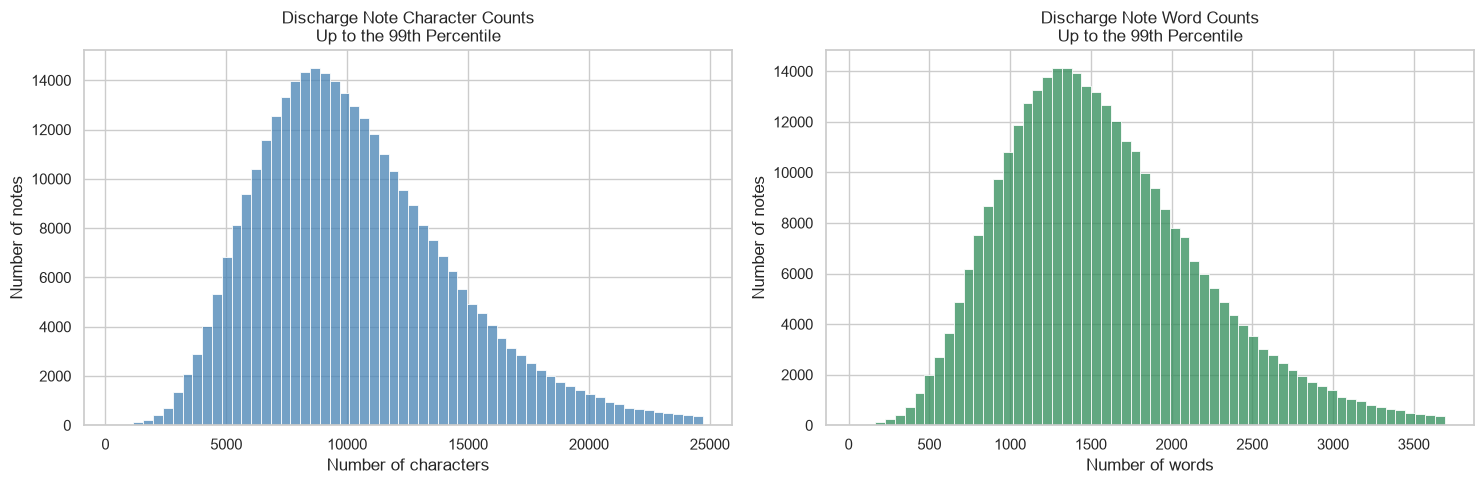

In [75]:
# Plot discharge note length distribution.

character_limit_99 = (
    character_count_series
    .quantile(0.99)
)

word_limit_99 = (
    word_count_series
    .quantile(0.99)
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


sns.histplot(
    character_count_series[
        character_count_series
        <= character_limit_99
    ],
    bins=60,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title(
    "Discharge Note Character Counts\n"
    "Up to the 99th Percentile"
)

axes[0].set_xlabel(
    "Number of characters"
)

axes[0].set_ylabel(
    "Number of notes"
)


sns.histplot(
    word_count_series[
        word_count_series
        <= word_limit_99
    ],
    bins=60,
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title(
    "Discharge Note Word Counts\n"
    "Up to the 99th Percentile"
)

axes[1].set_xlabel(
    "Number of words"
)

axes[1].set_ylabel(
    "Number of notes"
)


plt.tight_layout()

plt.show()

## 7. Discharge Detail Exploration

In [76]:
# Explore Discharge detail table - discharge_detail.csv.gz

discharge_detail = pd.read_csv(
    FILE_PATHS["discharge_detail"]
)


discharge_detail_row_count = len(
    discharge_detail
)


print(
    "Discharge-detail shape:",
    discharge_detail.shape
)

print(
    "Discharge-detail columns:"
)

print(
    discharge_detail.columns.tolist()
)


discharge_detail_missing_summary = pd.DataFrame(
    {
        "missing_count": (
            discharge_detail
            .isna()
            .sum()
        ),

        "missing_percentage": (
            discharge_detail
            .isna()
            .mean()
            .mul(100)
            .round(2)
        )
    }
).sort_values(
    by="missing_percentage",
    ascending=False
)


display(
    discharge_detail_missing_summary
)


if "note_id" in discharge_detail.columns:

    detail_note_ids = set(
        discharge_detail[
            "note_id"
        ]
        .dropna()
        .astype(str)
    )

    detail_duplicate_note_ids = (
        discharge_detail[
            "note_id"
        ]
        .duplicated()
        .sum()
    )

    detail_ids_missing_from_discharge = (
        detail_note_ids
        - discharge_note_ids
    )

    discharge_ids_without_detail = (
        discharge_note_ids
        - detail_note_ids
    )

    print(
        "Unique discharge-detail note IDs:",
        len(detail_note_ids)
    )

    print(
        "Duplicate discharge-detail note IDs:",
        detail_duplicate_note_ids
    )

    print(
        "Detail note IDs missing from discharge:",
        len(detail_ids_missing_from_discharge)
    )

    print(
        "Discharge notes without detail records:",
        len(discharge_ids_without_detail)
    )


del discharge_detail

gc.collect()

Discharge-detail shape: (186138, 5)
Discharge-detail columns:
['note_id', 'subject_id', 'field_name', 'field_value', 'field_ordinal']


,missing_count,missing_percentage
note_id,0,0.0
subject_id,0,0.0
field_name,0,0.0
field_value,0,0.0
field_ordinal,0,0.0


Unique discharge-detail note IDs: 186138
Duplicate discharge-detail note IDs: 0
Detail note IDs missing from discharge: 0
Discharge notes without detail records: 145655


9195

## 8. Cross-table Linkage Checks

In [77]:
# Explore links between tables.

discharge_patients_in_patients_table = (
    discharge_subject_ids
    & patient_subject_ids
)

discharge_patients_missing_from_patients = (
    discharge_subject_ids
    - patient_subject_ids
)

discharge_admissions_in_admissions_table = (
    discharge_hadm_ids
    & admission_hadm_ids
)

discharge_admissions_missing_from_admissions = (
    discharge_hadm_ids
    - admission_hadm_ids
)

discharge_admissions_with_diagnoses = (
    discharge_hadm_ids
    & diagnosis_hadm_ids
)

discharge_admissions_without_diagnoses = (
    discharge_hadm_ids
    - diagnosis_hadm_ids
)


linkage_summary = pd.DataFrame(
    {
        "linkage_check": [
            "Discharge patients",
            "Discharge patients matched to patients table",
            "Discharge patients missing from patients table",
            "Discharge admissions",
            "Discharge admissions matched to admissions table",
            "Discharge admissions missing from admissions table",
            "Discharge admissions with diagnosis records",
            "Discharge admissions without diagnosis records"
        ],

        "count": [
            len(discharge_subject_ids),
            len(discharge_patients_in_patients_table),
            len(discharge_patients_missing_from_patients),
            len(discharge_hadm_ids),
            len(discharge_admissions_in_admissions_table),
            len(discharge_admissions_missing_from_admissions),
            len(discharge_admissions_with_diagnoses),
            len(discharge_admissions_without_diagnoses)
        ]
    }
)


display(
    linkage_summary
)


if len(discharge_subject_ids) > 0:

    patient_linkage_percentage = (
        len(
            discharge_patients_in_patients_table
        )
        / len(
            discharge_subject_ids
        )
    ) * 100

else:

    patient_linkage_percentage = np.nan


if len(discharge_hadm_ids) > 0:

    admission_linkage_percentage = (
        len(
            discharge_admissions_in_admissions_table
        )
        / len(
            discharge_hadm_ids
        )
    ) * 100

    diagnosis_coverage_percentage = (
        len(
            discharge_admissions_with_diagnoses
        )
        / len(
            discharge_hadm_ids
        )
    ) * 100

else:

    admission_linkage_percentage = np.nan
    diagnosis_coverage_percentage = np.nan


print(
    "Discharge-patient linkage percentage:",
    round(
        patient_linkage_percentage,
        2
    )
)

print(
    "Discharge-admission linkage percentage:",
    round(
        admission_linkage_percentage,
        2
    )
)

print(
    "Discharge-admission diagnosis coverage:",
    round(
        diagnosis_coverage_percentage,
        2
    )
)

,linkage_check,count
0,Discharge patients,145914
1,Discharge patients matched to patients table,145895
2,Discharge patients missing from patients table,19
3,Discharge admissions,331793
4,Discharge admissions matched to admissions table,331732
5,Discharge admissions missing from admissions table,61
6,Discharge admissions with diagnosis records,331604
7,Discharge admissions without diagnosis records,189


Discharge-patient linkage percentage: 99.99
Discharge-admission linkage percentage: 99.98
Discharge-admission diagnosis coverage: 99.94


## 9. Final Exploration Summary

In [78]:
# Final summary

dataset_overview = pd.DataFrame(
    {
        "table": [
            "patients",
            "admissions",
            "diagnoses_icd",
            "d_icd_diagnoses",
            "discharge",
            "discharge_detail"
        ],

        "row_count": [
            patient_row_count,
            admission_row_count,
            diagnosis_row_count,
            diagnosis_dictionary_row_count,
            discharge_row_count,
            discharge_detail_row_count
        ],

        "primary_unique_identifier_count": [
            patient_unique_subject_count,
            admission_unique_hadm_count,
            diagnosis_unique_hadm_count,
            total_unique_codes,
            len(discharge_note_ids),
            len(detail_note_ids)
        ],

        "primary_identifier": [
            "subject_id",
            "hadm_id",
            "hadm_id",
            "icd_code + icd_version",
            "note_id",
            "note_id"
        ]
    }
)


display(
    dataset_overview
)

,table,row_count,primary_unique_identifier_count,primary_identifier
0,patients,364627,364627,subject_id
1,admissions,546028,546028,hadm_id
2,diagnoses_icd,6364488,545497,hadm_id
3,d_icd_diagnoses,112107,28583,icd_code + icd_version
4,discharge,331793,331793,note_id
5,discharge_detail,186138,186138,note_id


In [79]:
# Save exploration outputs

file_inventory.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "file_inventory.csv",
    index=False
)

schema_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "schema_summary.csv",
    index=False
)

patients_missing_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "patients_missing_summary.csv"
)

admissions_missing_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "admissions_missing_summary.csv"
)

diagnoses_missing_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "diagnoses_missing_summary.csv"
)

discharge_quality_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "discharge_quality_summary.csv",
    index=False
)

discharge_detail_missing_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "discharge_detail_missing_summary.csv"
)

linkage_summary.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "cross_table_linkage_summary.csv",
    index=False
)

dataset_overview.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "dataset_overview.csv",
    index=False
)

most_common_diagnoses.to_csv(
    EXPLORATION_OUTPUT_DIR
    / "most_common_diagnoses.csv",
    index=False
)


print(
    "Aggregate exploration outputs saved to:"
)

print(
    EXPLORATION_OUTPUT_DIR
)


print(
    "\nSaved files:"
)

for file_path in sorted(
    EXPLORATION_OUTPUT_DIR.iterdir()
):

    print(
        file_path.name
    )

Aggregate exploration outputs saved to:
/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/exploration_outputs

Saved files:
admissions_missing_summary.csv
cross_table_linkage_summary.csv
dataset_overview.csv
diagnoses_missing_summary.csv
discharge_detail_missing_summary.csv
discharge_quality_summary.csv
file_inventory.csv
most_common_diagnoses.csv
patients_missing_summary.csv
schema_summary.csv
